<a href="https://colab.research.google.com/github/Vedantsonawane-ngl/DS-experiments/blob/main/DVM.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
import requests

# Your OpenWeatherMap API key
API_KEY = "0afbf19831f03294c8111adfb03c9876"

# City name
city = "Pune"

# API URL
url = "https://api.openweathermap.org/data/2.5/forecast"

# Parameters to send to API
params = {
    "q": city,
    "appid": API_KEY,
    "units": "metric"
}

# Send request
response = requests.get(url, params=params)

# Check response
if response.status_code == 200:
    weather_data = response.json()
    print("API connection successful!")
else:
    print("Error:", response.status_code)
    print(response.text)

API connection successful!


In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Using the weather_data retrieved successfully from the previous cell
# Since the 5-day forecast returns a list of time blocks, we extract the first entry
first_forecast = weather_data["list"][0]

parsed_weather = {
    "Temperature": first_forecast["main"]["temp"],
    "Humidity": first_forecast["main"]["humidity"],
    "Wind Speed": first_forecast["wind"]["speed"],
    "Precipitation": first_forecast.get("rain", {}).get("3h", 0) # 5-day forecast provides rain in 3-hour blocks
}

print("Parsed weather data from forecast:")
print(parsed_weather)

Parsed weather data from forecast:
{'Temperature': 24.71, 'Humidity': 34, 'Wind Speed': 3.92, 'Precipitation': 0}


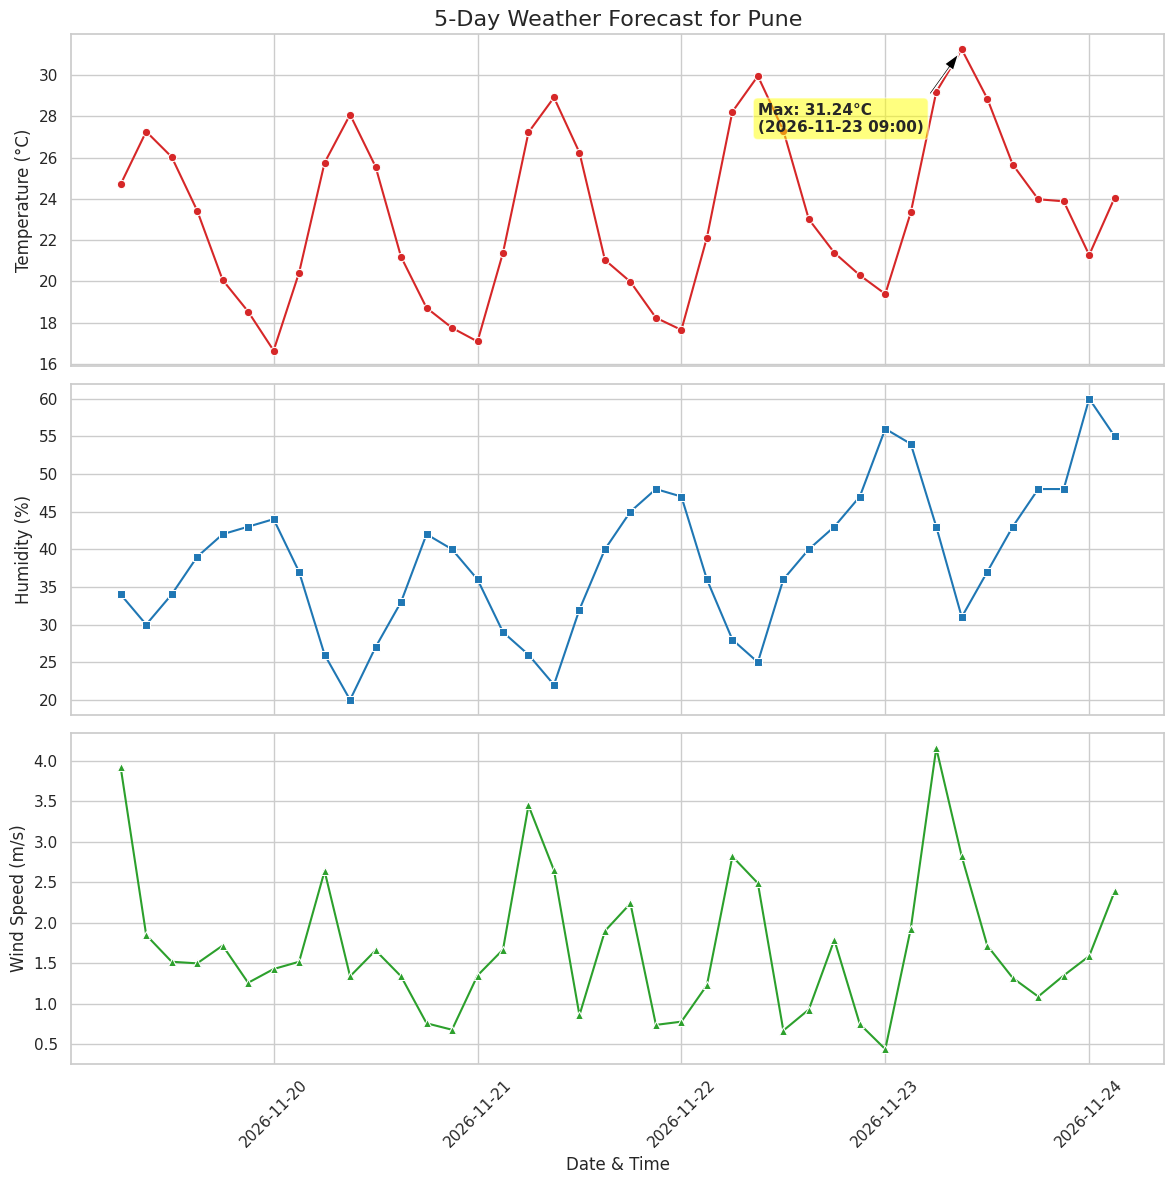

In [9]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Extract lists of forecast details
forecast_list = weather_data["list"]

timestamps = []
temps = []
humidities = []
wind_speeds = []

for f in forecast_list:
    timestamps.append(f["dt_txt"])
    temps.append(f["main"]["temp"])
    humidities.append(f["main"]["humidity"])
    wind_speeds.append(f["wind"]["speed"])

# Create a pandas DataFrame for analysis and plotting
df_forecast = pd.DataFrame({
    "DateTime": pd.to_datetime(timestamps),
    "Temperature": temps,
    "Humidity": humidities,
    "WindSpeed": wind_speeds
})

# Find the highest temperature point for annotation
max_temp_idx = df_forecast["Temperature"].idxmax()
max_temp_time = df_forecast.loc[max_temp_idx, "DateTime"]
max_temp_val = df_forecast.loc[max_temp_idx, "Temperature"]

# Set the aesthetic style
sns.set_theme(style="whitegrid")

# Create a dashboard of plots
fig, axes = plt.subplots(3, 1, figsize=(12, 12), sharex=True)

# 1. Temperature Plot with annotation
sns.lineplot(data=df_forecast, x="DateTime", y="Temperature", ax=axes[0], color="tab:red", marker="o")
axes[0].set_title(f"5-Day Weather Forecast for {city}", fontsize=16)
axes[0].set_ylabel("Temperature (°C)", fontsize=12)

# Annotate the maximum temperature point on the first plot
axes[0].annotate(
    f"Max: {max_temp_val}°C\n({max_temp_time.strftime('%Y-%m-%d %H:%M')})",
    xy=(max_temp_time, max_temp_val),
    xytext=(max_temp_time - pd.Timedelta(hours=24), max_temp_val - 4),
    arrowprops=dict(facecolor='black', shrink=0.08, width=1.5, headwidth=8),
    fontsize=11,
    fontweight='bold',
    bbox=dict(boxstyle="round,pad=0.3", fc="yellow", alpha=0.5)
)

# 2. Humidity Plot
sns.lineplot(data=df_forecast, x="DateTime", y="Humidity", ax=axes[1], color="tab:blue", marker="s")
axes[1].set_ylabel("Humidity (%)", fontsize=12)

# 3. Wind Speed Plot
sns.lineplot(data=df_forecast, x="DateTime", y="WindSpeed", ax=axes[2], color="tab:green", marker="^")
axes[2].set_ylabel("Wind Speed (m/s)", fontsize=12)
axes[2].set_xlabel("Date & Time", fontsize=12)

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [10]:
# Find the row with the maximum temperature
max_temp_row = df_forecast.loc[df_forecast['Temperature'].idxmax()]

print(f"Highest Temperature: {max_temp_row['Temperature']}°C")
print(f"Date & Time: {max_temp_row['DateTime']}")

Highest Temperature: 31.24°C
Date & Time: 2026-11-23 09:00:00
